In [1]:
# Runtime evidence: this cell checks the environment actually used by the kernel.
import sys as _shape_sys, json as _shape_json, importlib.util as _shape_util
print("SHAPE_RUNTIME_PROVENANCE=" + _shape_json.dumps({
    "python_executable": _shape_sys.executable,
    "python_version": _shape_sys.version.split()[0],
    "shape_lab_origin": _shape_util.find_spec("shape_lab").origin
}))
del _shape_sys, _shape_json, _shape_util


SHAPE_RUNTIME_PROVENANCE={"python_executable": "c:\\Users\\ghadf\\vscode_projects\\docker_projects\\topology\\.venv\\Scripts\\python.exe", "python_version": "3.13.5", "shape_lab_origin": "C:\\Users\\ghadf\\vscode_projects\\docker_projects\\topology\\src\\shape_lab\\__init__.py"}


# Stage 00 — Start here: how to learn, run, and question the results

Read `lessons/00_lesson.md` first. Predict each result before execution. This is a fully worked lab; independent exercises and solutions are separate. All real examples before Stage 12 restrict digit displays to training data.

## Setup
This cell locates the project, loads standard numerical tools, and creates only this stage’s output folder. The mathematical work begins below.

In [2]:
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib','inline')
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / "data/manifest.json").exists() and (p / "src/shape_lab").exists()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the extracted listening_to_shape_lab folder.")
sys.path.insert(0, str(ROOT / "src"))
from shape_lab.display import show_and_save, save_json
OUT = ROOT / "reports/stage_00"
OUT.mkdir(parents=True, exist_ok=True)
print("Output folder:", OUT.relative_to(ROOT))

Output folder: reports\stage_00


## Predict first
What does a 2×3 array contain? What is its first row? Run the cell and compare.

In [3]:
a = np.array([[1, 2, 3], [4, 5, 6]])
print("Array:", a, sep="\n")
print("Shape:", a.shape, "First row:", a[0])
print("First column:", a[:, 0])
assert a.shape == (2, 3)

Array:
[[1 2 3]
 [4 5 6]]
Shape: (2, 3) First row: [1 2 3]
First column: [1 4]


## Real data, not generated data
These flower measurements are the bundled scikit-learn Iris snapshot. The label and ID are not measurement columns.

In [4]:
from shape_lab.data import load_iris_data, load_digit_data
iris = load_iris_data()
print(iris.head(4).to_string(index=False))
print("Recorded Iris rows:", len(iris))
images, labels, ids = load_digit_data("train")
print("Training digits:", images.shape, "First sample ID:", ids[0])
print("First image label:", labels[0])

 sample_id  sepal_length_cm  sepal_width_cm  petal_length_cm  petal_width_cm  label species
         0              5.1             3.5              1.4             0.2      0  setosa
         1              4.9             3.0              1.4             0.2      0  setosa
         2              4.7             3.2              1.3             0.2      0  setosa
         3              4.6             3.1              1.5             0.2      0  setosa
Recorded Iris rows: 150
Training digits: (1077, 8, 8) First sample ID: 0
First image label: 0


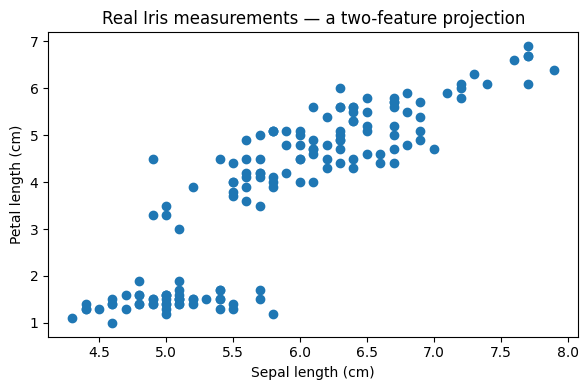

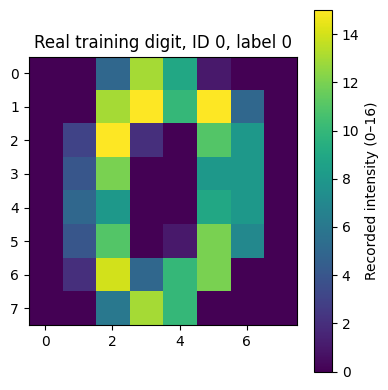

In [5]:
plt.figure(figsize=(6, 4))
plt.scatter(iris["sepal_length_cm"], iris["petal_length_cm"])
plt.xlabel("Sepal length (cm)"); plt.ylabel("Petal length (cm)")
plt.title("Real Iris measurements — a two-feature projection")
show_and_save(OUT / "iris_projection.png")
plt.figure(figsize=(4, 4))
plt.imshow(images[0]); plt.colorbar(label="Recorded intensity (0–16)")
plt.title(f"Real training digit, ID {ids[0]}, label {labels[0]}")
show_and_save(OUT / "training_digit.png")

In [6]:
assert len(iris) == 150
assert images.shape == (1077, 8, 8)
assert np.isfinite(images).all()
save_json(OUT / "results.json", {"iris_rows": len(iris), "training_digit_shape": images.shape,
          "first_training_id": int(ids[0]), "claim": "Data loading and plotting only; no topology inferred."})

## Explain before continuing
Which plot depicts all four Iris features? Neither: the scatter plot uses only two. A successful image display is not a homology calculation. Complete the Stage 00 exercises.

## Mastery gate
Run Stage 00, explain its data shapes and provenance, and distinguish code execution from understanding.

A successful Run All is computational evidence, not a learner pass. Complete the lesson’s original exercises before reading `solutions/00_solutions.md`. Record independent work, corrections and a delayed re-test in your learner ledger.

## Sources and conventions
Source IDs: D3, R1; direct links and assignments are in `docs/SOURCES.md`. Core conventions are in `docs/MATHEMATICAL_CONVENTIONS.md`.